#RouteAI uses ML and graph algos to optimize the path 

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
import random

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error

In [4]:
np.random.seed(42)

num_nodes = 20
num_roads = 60
road_types = ["Highway", "Main road", "Residential", "Street"]

roads_df = pd.DataFrame({
    "road_id": range(1, num_roads + 1),
    "source_node": np.random.randint(0, num_nodes, size=num_roads),
    "destination_node": np.random.randint(0, num_nodes, size=num_roads),
    "distance_km": np.round(np.random.uniform(1, 15, size=num_roads), 2),
    "road_type": np.random.choice(road_types, size=num_roads),
    "speed_limit_kmph": np.random.choice([30, 40, 50, 60, 80, 100], size=num_roads),
})

# remove self-loops (a road can't start and end at the same node)
roads_df = roads_df[roads_df["source_node"] != roads_df["destination_node"]].reset_index(drop=True)

roads_df.head()

,road_id,source_node,destination_node,distance_km,road_type,speed_limit_kmph
0,1,6,3,1.44,Street,100
1,2,19,13,9.91,Highway,60
2,3,14,15,5.40,Street,80
3,4,10,14,8.12,Main road,80
4,6,6,13,4.49,Main road,30


In [5]:
rows = []

for _, r in roads_df.iterrows():
    for hour in range(24):
        for day in range(7):  # 0=Mon ... 6=Sun
            if hour in [8, 9, 17, 18]:
                congestion_factor = np.random.uniform(1.5, 2.2)
            elif 0 <= hour <= 4:
                congestion_factor = np.random.uniform(0.8, 1.0)
            else:
                congestion_factor = np.random.uniform(1.0, 1.4)

            avg_speed = max(r["speed_limit_kmph"] / congestion_factor, 5)

            rows.append({
                "road_id": r["road_id"],
                "hour_of_day": hour,
                "day_of_week": day,
                "avg_speed_kmph": round(avg_speed, 2),
            })

traffic_df = pd.DataFrame(rows)
traffic_df.head()

,road_id,hour_of_day,day_of_week,avg_speed_kmph
0,1,0,0,111.05
1,1,0,1,109.24
2,1,0,2,111.30
3,1,0,3,119.18
4,1,0,4,105.88


In [6]:
data = traffic_df.merge(roads_df, on="road_id")

data["travel_time_min"] = (data["distance_km"] / data["avg_speed_kmph"]) * 60

data.head()

,road_id,hour_of_day,day_of_week,avg_speed_kmph,source_node,destination_node,distance_km,road_type,speed_limit_kmph,travel_time_min
0,1,0,0,111.05,6,3,1.44,Street,100,0.778028
1,1,0,1,109.24,6,3,1.44,Street,100,0.790919
2,1,0,2,111.30,6,3,1.44,Street,100,0.776280
3,1,0,3,119.18,6,3,1.44,Street,100,0.724954
4,1,0,4,105.88,6,3,1.44,Street,100,0.816018


In [8]:
roads_df.to_csv("../data/raw/roads.csv", index=False)
data.to_csv("../data/raw/traffic_data.csv", index=False)

print("Saved roads.csv:", roads_df.shape)
print("Saved traffic_data.csv:", data.shape)

Saved roads.csv: (54, 6)
Saved traffic_data.csv: (9072, 10)


In [9]:
print(data.info())
print(data.describe())
print(data.isnull().sum())

<class 'pandas.DataFrame'>
RangeIndex: 9072 entries, 0 to 9071
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   road_id           9072 non-null   int64  
 1   hour_of_day       9072 non-null   int64  
 2   day_of_week       9072 non-null   int64  
 3   avg_speed_kmph    9072 non-null   float64
 4   source_node       9072 non-null   int32  
 5   destination_node  9072 non-null   int32  
 6   distance_km       9072 non-null   float64
 7   road_type         9072 non-null   str    
 8   speed_limit_kmph  9072 non-null   int64  
 9   travel_time_min   9072 non-null   float64
dtypes: float64(3), int32(2), int64(4), str(1)
memory usage: 638.0 KB
None
           road_id  hour_of_day  day_of_week  avg_speed_kmph  source_node  \
count  9072.000000  9072.000000   9072.00000     9072.000000  9072.000000   
mean     30.629630    11.500000      3.00000       53.887036     9.740741   
std      17.792256     6.922568   

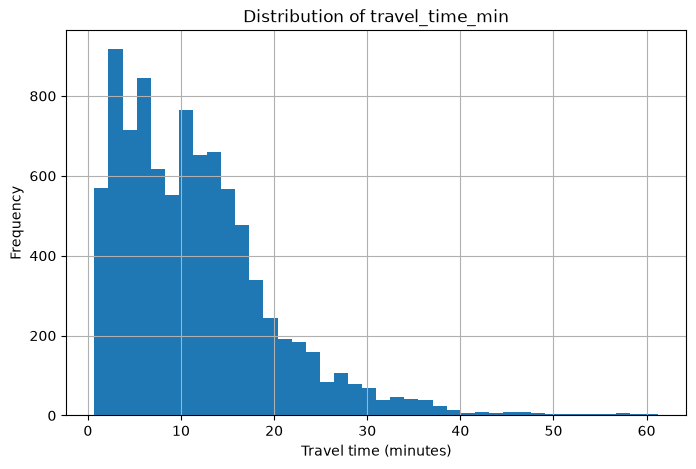

In [10]:
plt.figure(figsize=(8,5))
data["travel_time_min"].hist(bins=40)
plt.xlabel("Travel time (minutes)")
plt.ylabel("Frequency")
plt.title("Distribution of travel_time_min")
plt.show()

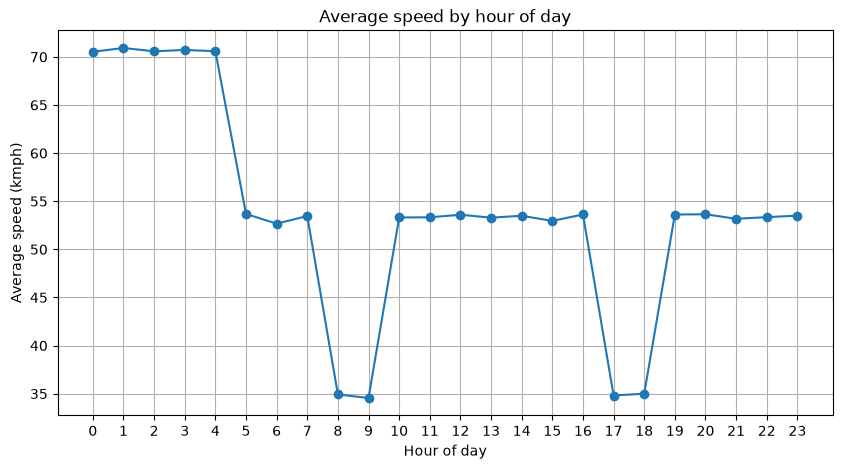

In [11]:
hourly_avg = data.groupby("hour_of_day")["avg_speed_kmph"].mean()

plt.figure(figsize=(10,5))
hourly_avg.plot(kind="line", marker="o")
plt.xlabel("Hour of day")
plt.ylabel("Average speed (kmph)")
plt.title("Average speed by hour of day")
plt.xticks(range(0,24))
plt.grid(True)
plt.show()

In [12]:
# Step 1: One-hot encode road_type
data_enc = pd.get_dummies(data, columns=["road_type"], drop_first=True)

# Step 2: Cyclical encoding for hour_of_day
data_enc["hour_sin"] = np.sin(2 * np.pi * data_enc["hour_of_day"] / 24)
data_enc["hour_cos"] = np.cos(2 * np.pi * data_enc["hour_of_day"] / 24)

# Step 3: Define our final feature list (LEAKAGE-SAFE)
feature_cols = ["distance_km", "speed_limit_kmph", "hour_sin", "hour_cos", "day_of_week"] + \
               [c for c in data_enc.columns if c.startswith("road_type_")]

target_col = "travel_time_min"

X = data_enc[feature_cols]
y = data_enc[target_col]

print("Features used:", feature_cols)
print("X shape:", X.shape)
print("y shape:", y.shape)
X.head()

Features used: ['distance_km', 'speed_limit_kmph', 'hour_sin', 'hour_cos', 'day_of_week', 'road_type_Main road', 'road_type_Residential', 'road_type_Street']
X shape: (9072, 8)
y shape: (9072,)


,distance_km,speed_limit_kmph,hour_sin,hour_cos,day_of_week,road_type_Main road,road_type_Residential,road_type_Street
0,1.44,100,0.0,1.0,0,False,False,True
1,1.44,100,0.0,1.0,1,False,False,True
2,1.44,100,0.0,1.0,2,False,False,True
3,1.44,100,0.0,1.0,3,False,False,True
4,1.44,100,0.0,1.0,4,False,False,True


In [13]:
data_enc[[c for c in data_enc.columns if c.startswith("road_type_")]] = \
    data_enc[[c for c in data_enc.columns if c.startswith("road_type_")]].astype(int)

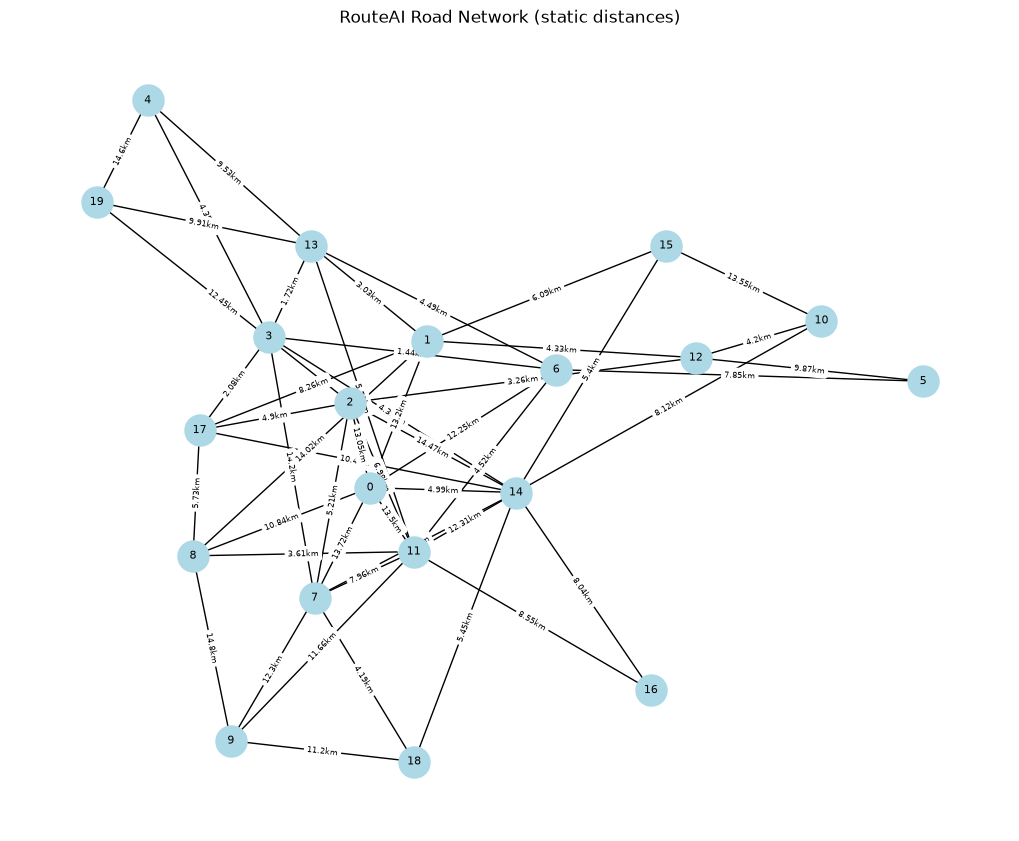

In [14]:
G = nx.Graph()

for _, r in roads_df.iterrows():
    G.add_edge(
        r["source_node"],
        r["destination_node"],
        distance=r["distance_km"],
        road_type=r["road_type"]
    )

plt.figure(figsize=(10, 8))
pos = nx.spring_layout(G, seed=42)
nx.draw(G, pos, with_labels=True, node_color="lightblue", node_size=500, font_size=8)
edge_labels = {(u, v): f"{d['distance']}km" for u, v, d in G.edges(data=True)}
nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_size=6)
plt.title("RouteAI Road Network (static distances)")
plt.show()

In [15]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

from sklearn.ensemble import RandomForestRegressor

dt_model = DecisionTreeRegressor(max_depth=8, random_state=42)
dt_model.fit(X_train, y_train)
dt_preds = dt_model.predict(X_test)
dt_mae = mean_absolute_error(y_test, dt_preds)

rf_model = RandomForestRegressor(n_estimators=100, max_depth=10, random_state=42)
rf_model.fit(X_train, y_train)
rf_preds = rf_model.predict(X_test)
rf_mae = mean_absolute_error(y_test, rf_preds)

print(f"Decision Tree MAE: {dt_mae:.3f} minutes")
print(f"Random Forest MAE: {rf_mae:.3f} minutes")

Decision Tree MAE: 1.181 minutes
Random Forest MAE: 1.004 minutes


Random Forest RMSE: 1.524 minutes
Random Forest R²: 0.965


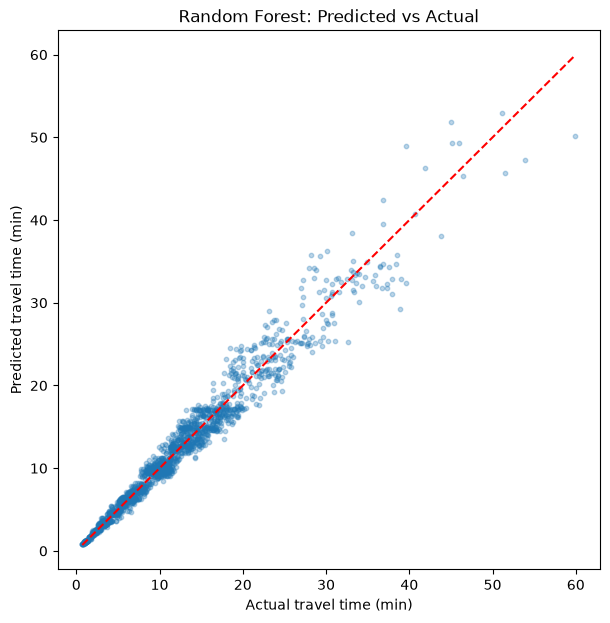

distance_km              0.440600
speed_limit_kmph         0.386035
hour_sin                 0.081975
hour_cos                 0.076517
day_of_week              0.007459
road_type_Residential    0.004745
road_type_Street         0.002102
road_type_Main road      0.000566
dtype: float64


In [16]:
from sklearn.metrics import mean_squared_error, r2_score

rf_rmse = mean_squared_error(y_test, rf_preds) ** 0.5
rf_r2 = r2_score(y_test, rf_preds)

print(f"Random Forest RMSE: {rf_rmse:.3f} minutes")
print(f"Random Forest R²: {rf_r2:.3f}")

plt.figure(figsize=(7,7))
plt.scatter(y_test, rf_preds, alpha=0.3, s=10)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--")
plt.xlabel("Actual travel time (min)")
plt.ylabel("Predicted travel time (min)")
plt.title("Random Forest: Predicted vs Actual")
plt.show()

importances = pd.Series(rf_model.feature_importances_, index=feature_cols).sort_values(ascending=False)
print(importances)

In [18]:
def predict_travel_time(road_row, hour, day, model, feature_cols):
    hour_sin = np.sin(2 * np.pi * hour / 24)
    hour_cos = np.cos(2 * np.pi * hour / 24)
    
    row = {
        "distance_km": road_row["distance_km"],
        "speed_limit_kmph": road_row["speed_limit_kmph"],
        "hour_sin": hour_sin,
        "hour_cos": hour_cos,
        "day_of_week": day,
    }
    for col in feature_cols:
        if col.startswith("road_type_"):
            row[col] = 1 if col == f"road_type_{road_row['road_type']}" else 0
    
    X_row = pd.DataFrame([row])[feature_cols]
    return model.predict(X_row)[0]

chosen_hour = 8
chosen_day = 0

G_smart = nx.DiGraph()

for _, r in roads_df.iterrows():
    predicted_time = predict_travel_time(r, chosen_hour, chosen_day, rf_model, feature_cols)
    G_smart.add_edge(r["source_node"], r["destination_node"], weight=predicted_time, distance=r["distance_km"])
    G_smart.add_edge(r["destination_node"], r["source_node"], weight=predicted_time, distance=r["distance_km"])

source, target = 0, 15
path = nx.shortest_path(G_smart, source=source, target=target, weight="weight")
travel_time = nx.shortest_path_length(G_smart, source=source, target=target, weight="weight")

print(f"Fastest route from {source} to {target} at hour {chosen_hour}: {path}")
print(f"Predicted total travel time: {travel_time:.2f} minutes")

Fastest route from 0 to 15 at hour 8: [0, 14, 15]
Predicted total travel time: 17.34 minutes


In [19]:
import joblib

joblib.dump(rf_model, "../models/rf_travel_time_model.pkl")
joblib.dump(feature_cols, "../models/feature_cols.pkl")

print("Model and feature list saved.")

# Quick reload test — proves the saved file actually works
loaded_model = joblib.load("../models/rf_travel_time_model.pkl")
loaded_features = joblib.load("../models/feature_cols.pkl")

test_pred = loaded_model.predict(X_test.iloc[[0]])
print("Reloaded model prediction on first test row:", test_pred)
print("Original model prediction on same row:", rf_model.predict(X_test.iloc[[0]]))

Model and feature list saved.
Reloaded model prediction on first test row: [5.27277708]
Original model prediction on same row: [5.27277708]
